# Step 6: Dual-Space SHAP Model Interpretability & Governance
## Healthcare Appointment No-Show Risk Optimization

### 1. Milestone Overview & Clinical Motivation
In **Step 4**, we benchmarked multiple machine learning architectures on a leakage-safe chronological temporal split and selected the **unweighted XGBoost classifier** ($PR\text{-}AUC = 0.3584$, $ROC\text{-}AUC = 0.7382$, Brier score = $0.1431$). In **Step 5**, operational cost analysis established that a business-tuned decision threshold of $0.15$ achieves $93.62\%$ recall and saves an estimated $\$98,920.00$ over baseline operations.

However, clinical teams, nurses, and patient navigators cannot act on abstract mathematical quantities like log-odds margins ($z \in (-\infty, +\infty)$). Healthcare decision-makers need to know **how much each patient characteristic directly increases or decreases the probability of a missed appointment**.

This notebook implements **Dual-Space SHAP (SHapley Additive exPlanations)** grounded in cooperative game theory:
1. **Technical Reference (Raw-Margin SHAP):** Evaluates tree attributions in log-odds margin space using an interventional background reference.
2. **Primary Stakeholder Interpretation (Probability-Space SHAP):** Uses the exact same empirical training background dataset ($N=200$ supplied, effective $N=100$ evaluated) and interventional TreeExplainer to produce exact, direct contributions in **probability points** and **percentage points (% pts)**:
   $$P(\text{no-show} \mid x) = \phi_0 + \sum_{i=1}^{n} \phi_i$$

---

### Core Questions Answered in Probability Space:
1. **Which features exert the greatest overall influence on predicted no-show probability?**
2. **How many percentage points does scheduling lead time, age, or past history add to or subtract from patient risk?**
3. **What non-linear probability thresholds exist across appointment lead time and patient lifespan?**
4. **Why does the model flag individual patients (High-Risk, Low-Risk, and False-Positive cases) relative to the clinic baseline?**

> **Fundamental Governance Principle:**
> SHAP explains **model behavior and statistical associations**, not clinical causality. A contribution of $+0.05$ means a $+5$ percentage-point contribution to the model's predicted probability relative to the reference baseline. It does *not* prove that altering that feature in the real world will causally change attendance.

In [1]:
import os
import sys
import json
import joblib
import warnings
import scipy.sparse
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

# Suppress benign warnings
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

# Styling configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 150

print(f"Python Version:       {sys.version.split()[0]}")
print(f"SHAP Version:         {shap.__version__}")
import xgboost as xgb
print(f"XGBoost Version:      {xgb.__version__}")
import sklearn
print(f"scikit-learn Version: {sklearn.__version__}")
print(f"NumPy Version:        {np.__version__}")
print(f"Pandas Version:       {pd.__version__}")

C:\Users\gaura\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python Version:       3.14.7
SHAP Version:         0.52.0
XGBoost Version:      3.4.1
scikit-learn Version: 1.9.0
NumPy Version:        2.5.2
Pandas Version:       3.0.5


### 2. Loading Pipeline, Defensive Data Integrity Checks, and Sampling

#### Sampling Methodology & Effective Background Size:
1. **Background Dataset (Train Only, $N=200$ Supplied, Effective $N=100$ Used):**
   - Sampled exclusively from `train_features.csv` using `np.random.default_rng(42)`.
   - When passed directly as `data=X_bg_trans`, SHAP's internal `Independent` masker applies its default `max_samples=100` using `sklearn.utils.shuffle(X, n_samples=100, random_state=0)`.
   - The **effective background size** evaluated internally by TreeExplainer for both raw-margin and probability-space is **100 observations**.
2. **Explanation Sample (Validation, $N=2,000$, Seed=42):**
   - Sampled reproducibly from the chronological validation partition (`val_features.csv`, May 20 – May 31, 2016) using `np.random.default_rng(42)`.
3. **Pre-Execution Integrity Audit:**
   - Validates row counts (20,539), binary target labels ($\{0, 1\}$), bounded probabilities ($[0, 1]$), label parity, and pipeline prediction parity.

#### Prediction Invariance Under Supported Configuration:
- When trained in Step 4, `clf.enable_categorical=True` was retained on the estimator. Because `ColumnTransformer` transforms all features into continuous and one-hot floats, the underlying booster contains zero categorical splits.
- Setting `clf.enable_categorical = False` informs SHAP's C++ parser that splits are numerical. We explicitly verify that this parameter change causes **exact zero difference** ($0.00 \times 10^0$) in predicted probabilities or raw margins.

In [2]:
# Dynamically detect project root regardless of notebook launch directory
curr = os.path.abspath(os.getcwd())
PROJECT_ROOT = curr
for _ in range(5):
    if os.path.exists(os.path.join(curr, 'data', 'processed', 'feature_metadata.json')):
        PROJECT_ROOT = curr
        break
    parent = os.path.dirname(curr)
    if parent == curr:
        break
    curr = parent

TRAIN_DATA_PATH = os.path.join(PROJECT_ROOT, 'data', 'processed', 'train_features.csv')
VAL_DATA_PATH = os.path.join(PROJECT_ROOT, 'data', 'processed', 'val_features.csv')
VAL_PRED_PATH = os.path.join(PROJECT_ROOT, 'data', 'processed', 'val_predictions_xgb_unweighted.csv')
METADATA_PATH = os.path.join(PROJECT_ROOT, 'data', 'processed', 'feature_metadata.json')
MODEL_PATH = os.path.join(PROJECT_ROOT, 'models', 'xgboost_unweighted.joblib')
FIGURES_DIR = os.path.join(PROJECT_ROOT, 'steps', '06_shap_explainability', 'figures')
os.makedirs(FIGURES_DIR, exist_ok=True)

# Output Paths
OUTPUT_RAW_TRANS_CSV = os.path.join(PROJECT_ROOT, 'data', 'processed', 'shap_feature_importance.csv')
OUTPUT_RAW_GROUPED_CSV = os.path.join(PROJECT_ROOT, 'data', 'processed', 'shap_grouped_feature_importance.csv')
OUTPUT_PROB_TRANS_CSV = os.path.join(PROJECT_ROOT, 'data', 'processed', 'shap_probability_feature_importance.csv')
OUTPUT_PROB_GROUPED_CSV = os.path.join(PROJECT_ROOT, 'data', 'processed', 'shap_probability_grouped_feature_importance.csv')
OUTPUT_PROB_LOCAL_CSV = os.path.join(PROJECT_ROOT, 'data', 'processed', 'shap_probability_local_explanations.csv')

# 1. Load metadata & pipeline
with open(METADATA_PATH, 'r', encoding='utf-8') as f:
    meta = json.load(f)
approved_features = meta['features']['explicit_list']
pipe = joblib.load(MODEL_PATH)
prep = pipe.named_steps['prep']
clf = pipe.named_steps['clf']

# 2. Load datasets
train_df = pd.read_csv(TRAIN_DATA_PATH)
val_df = pd.read_csv(VAL_DATA_PATH)
val_preds = pd.read_csv(VAL_PRED_PATH)

# Defensive integrity assertions
assert len(val_preds) == len(val_df), f"Row count mismatch: {len(val_preds)} vs {len(val_df)}"
assert set(val_df['no_show'].unique()).issubset({0, 1}), "Target must be binary {0, 1}"
assert set(val_preds['y_true'].unique()).issubset({0, 1}), "Saved labels must be binary {0, 1}"
assert np.all(np.isfinite(val_preds['y_prob_unweighted'])), "Probabilities must be finite"
assert (val_preds['y_prob_unweighted'].between(0.0, 1.0)).all(), "Probabilities must lie in [0, 1]"
assert np.array_equal(val_preds['y_true'].values, val_df['no_show'].values), "Saved labels do not match validation labels!"
print(f"Data Integrity Checks: PASSED (20,539 rows aligned, binary labels, probabilities bounded)")

val_df['pred_prob'] = val_preds['y_prob_unweighted']

# 3. Background dataset: 200 training observations supplied, seed 42 via default_rng
rng = np.random.default_rng(42)
bg_indices = rng.choice(len(train_df), size=200, replace=False)
bg_indices.sort()
X_bg_trans = prep.transform(train_df.iloc[bg_indices][approved_features])
if scipy.sparse.issparse(X_bg_trans):
    X_bg_trans = X_bg_trans.toarray()
elif hasattr(X_bg_trans, 'toarray'):
    X_bg_trans = X_bg_trans.toarray()
print(f"Background Dataset Supplied: {X_bg_trans.shape[0]} rows x {X_bg_trans.shape[1]} cols (Train only, Seed=42)")

# 4. Explanation sample: 2,000 validation observations, seed 42 via default_rng
val_sample_indices = rng.choice(len(val_df), size=min(2000, len(val_df)), replace=False)
val_sample_indices.sort()
val_sample = val_df.iloc[val_sample_indices].copy().reset_index(drop=True)
X_val_trans = prep.transform(val_sample[approved_features])
if scipy.sparse.issparse(X_val_trans):
    X_val_trans = X_val_trans.toarray()
elif hasattr(X_val_trans, 'toarray'):
    X_val_trans = X_val_trans.toarray()
print(f"Explanation Sample:          {X_val_trans.shape[0]} rows x {X_val_trans.shape[1]} cols (Validation Set, Seed=42)")

# Prediction parity check on sample
sample_fresh_probs = pipe.predict_proba(val_sample[approved_features])[:, 1]
parity_diff = np.max(np.abs(sample_fresh_probs - val_sample['pred_prob'].values))
np.testing.assert_allclose(sample_fresh_probs, val_sample['pred_prob'].values, atol=1e-4)
print(f"Prediction Parity:           PASSED (Max difference = {parity_diff:.2e})")

# 5. Prediction invariance check under clf.enable_categorical = False
probs_pre = clf.predict_proba(X_val_trans)[:, 1]
margins_pre = clf.predict(X_val_trans, output_margin=True)
margins_pre_pos = margins_pre[:, 1] if len(margins_pre.shape) > 1 and margins_pre.shape[1] > 1 else margins_pre.ravel()

clf.enable_categorical = False

probs_post = clf.predict_proba(X_val_trans)[:, 1]
margins_post = clf.predict(X_val_trans, output_margin=True)
margins_post_pos = margins_post[:, 1] if len(margins_post.shape) > 1 and margins_post.shape[1] > 1 else margins_post.ravel()

prob_invar_diff = float(np.max(np.abs(probs_pre - probs_post)))
margin_invar_diff = float(np.max(np.abs(margins_pre_pos - margins_post_pos)))
assert prob_invar_diff == 0.0, f"Setting enable_categorical altered probabilities: {prob_invar_diff}"
assert margin_invar_diff == 0.0, f"Setting enable_categorical altered margins: {margin_invar_diff}"
print(f"enable_categorical Parity:   PASSED (Exact diff = {prob_invar_diff:.2e} for prob and margin)")

Data Integrity Checks: PASSED (20,539 rows aligned, binary labels, probabilities bounded)
Background Dataset Supplied: 200 rows x 25 cols (Train only, Seed=42)
Explanation Sample:          2000 rows x 25 cols (Validation Set, Seed=42)
Prediction Parity:           PASSED (Max difference = 2.68e-08)
enable_categorical Parity:   PASSED (Exact diff = 0.00e+00 for prob and margin)


### 3. Exact Feature Mapping (Eliminating Substring Overlaps)

To ensure that multi-component features (such as one-hot encoded days of week) are grouped unambiguously into their conceptual original features without prefix confusion (e.g., distinguishing `prior_noshows`, `prior_noshow_rate`, and `prior_appointments`), we inspect the transformer blocks in `ColumnTransformer.transformers_` directly:
- **Categorical (`OneHotEncoder`):** Iterate through `zip(input_cols, trans.categories_)`, respecting `drop='first'`.
- **Numeric & Binary:** Direct 1-to-1 identity mapping to column names.
- **Strict Integrity Assertion:** Every transformed feature maps to exactly one approved predictor feature.

In [3]:
feature_names_out = list(prep.get_feature_names_out())
clean_names = [f.split('__')[1] if '__' in f else f for f in feature_names_out]

col_to_orig = {}
for trans_name, trans_obj, input_cols in prep.transformers_:
    if trans_name == 'remainder' and trans_obj == 'drop':
        continue
    if trans_name == 'cat':
        for col_name, cat_list in zip(input_cols, trans_obj.categories_):
            kept_cats = cat_list[1:] if trans_obj.drop == 'first' else cat_list
            for cat_val in kept_cats:
                col_to_orig[f'cat__{col_name}_{cat_val}'] = col_name
    elif trans_name in ('num', 'bin'):
        for col_name in input_cols:
            col_to_orig[f'{trans_name}__{col_name}'] = col_name

assert len(col_to_orig) == len(feature_names_out), f"Mapping count mismatch: {len(col_to_orig)} vs {len(feature_names_out)}"
assert set(col_to_orig.keys()) == set(feature_names_out), "Transformed feature set mismatch!"
assert all(orig in approved_features for orig in col_to_orig.values()), "Unknown original features detected!"
print(f"Mapped {len(feature_names_out)} transformed columns to {len(approved_features)} original features.")

# Prepare unstandardized data copy for human-readable scatter and waterfall plots
readable_data = X_val_trans.copy()
num_cols = ['age', 'lead_days', 'prior_appointments', 'prior_noshows', 'prior_noshow_rate', 'days_since_last_appointment']
for col in num_cols:
    if col in clean_names:
        idx = clean_names.index(col)
        readable_data[:, idx] = val_sample[col].values

Mapped 25 transformed columns to 17 original features.


### 4. Technical Reference: Raw-Margin SHAP (Log-Odds Margin)

Before deploying stakeholder-facing probability explanations, we preserve the **raw-margin SHAP analysis** as a technical engineering baseline. Both raw-margin and probability-space explainers share the exact same background dataset (`data=X_bg_trans`) and interventional perturbation (`feature_perturbation='interventional'`).

In raw margin mode:
$$z(x) = \phi_0 + \sum_{j=1}^{M} \phi_j(x)$$
where $\phi_0$ is the expected log-odds under interventional background marginalization, and $\sigma(z)$ yields the predicted positive-class probability.

We verify:
1. Reconstructed raw margin equals `clf.predict(X_trans, output_margin=True)` within $< 10^{-4}$.
2. Sigmoid transformation reproduces pipeline probabilities within $< 10^{-4}$.

In [4]:
# 1. Raw-margin TreeExplainer (Interventional with training background)
explainer_raw = shap.TreeExplainer(
    clf,
    data=X_bg_trans,
    feature_perturbation='interventional',
    model_output='raw'
)
shap_obj_raw = explainer_raw(X_val_trans)

# Base value extraction (raw margin space)
if isinstance(explainer_raw.expected_value, (list, np.ndarray)):
    base_val_raw = float(explainer_raw.expected_value[1] if len(explainer_raw.expected_value) > 1 else explainer_raw.expected_value[0])
elif hasattr(shap_obj_raw, 'base_values'):
    bv = shap_obj_raw.base_values
    base_val_raw = float(bv[0, 1] if len(bv.shape) > 1 and bv.shape[1] > 1 else (bv[0] if len(bv.shape) > 0 else bv))
else:
    base_val_raw = float(explainer_raw.expected_value)

shap_vals_raw_pos = shap_obj_raw.values[:, :, 1] if len(shap_obj_raw.values.shape) == 3 else shap_obj_raw.values

# 2. Additivity & Parity Assertions
raw_margins = clf.predict(X_val_trans, output_margin=True)
raw_margins_pos = raw_margins[:, 1] if (len(raw_margins.shape) > 1 and raw_margins.shape[1] > 1) else raw_margins.ravel()
reconstructed_raw_margins = base_val_raw + np.sum(shap_vals_raw_pos, axis=1)
max_raw_add_err = float(np.max(np.abs(reconstructed_raw_margins - raw_margins_pos)))
np.testing.assert_allclose(reconstructed_raw_margins, raw_margins_pos, atol=1e-4)

reconstructed_raw_probs = 1.0 / (1.0 + np.exp(-raw_margins_pos))
max_raw_prob_err = float(np.max(np.abs(reconstructed_raw_probs - sample_fresh_probs)))
np.testing.assert_allclose(reconstructed_raw_probs, sample_fresh_probs, atol=1e-4)

print(f"Raw Base Value (log-odds):             {base_val_raw:.4f}")
print(f"Raw Additivity Assertion:             PASSED (Max error = {max_raw_add_err:.2e})")
print(f"Raw Sigmoid Probability Parity:       PASSED (Max error = {max_raw_prob_err:.2e})")

# 3. Export Raw CSVs
mean_abs_raw_trans = np.mean(np.abs(shap_vals_raw_pos), axis=0)
df_raw_trans_imp = pd.DataFrame({
    'transformed_feature': feature_names_out,
    'clean_name': clean_names,
    'original_feature': [col_to_orig[c] for c in feature_names_out],
    'mean_abs_shap': mean_abs_raw_trans
}).sort_values('mean_abs_shap', ascending=False).reset_index(drop=True)
df_raw_trans_imp['rank'] = df_raw_trans_imp.index + 1
df_raw_trans_imp.to_csv(OUTPUT_RAW_TRANS_CSV, index=False)

grouped_raw_records = []
for orig in approved_features:
    cols_idx = [i for i, col in enumerate(feature_names_out) if col_to_orig[col] == orig]
    if cols_idx:
        obs_contrib = np.sum(shap_vals_raw_pos[:, cols_idx], axis=1)
        grouped_raw_records.append({
            'original_feature': orig,
            'mean_abs_shap': float(np.mean(np.abs(obs_contrib))),
            'mean_signed_shap': float(np.mean(obs_contrib))
        })

df_raw_grouped_imp = pd.DataFrame(grouped_raw_records).sort_values('mean_abs_shap', ascending=False).reset_index(drop=True)
df_raw_grouped_imp['rank'] = df_raw_grouped_imp.index + 1
df_raw_grouped_imp.to_csv(OUTPUT_RAW_GROUPED_CSV, index=False)

print(f"Preserved Technical CSVs: {OUTPUT_RAW_TRANS_CSV} and {OUTPUT_RAW_GROUPED_CSV}")

# 4. Construct Class-Specific Raw Explanation Object
exp_raw_pos = shap.Explanation(
    values=shap_vals_raw_pos,
    base_values=np.full(len(val_sample), base_val_raw),
    data=readable_data,
    feature_names=clean_names
)

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


 83%|=================   | 1660/2000 [00:11<00:02]       

 91%|==================  | 1822/2000 [00:12<00:01]       

 99%|===================| 1979/2000 [00:13<00:00]       

Raw Base Value (log-odds):             -1.8167
Raw Additivity Assertion:             PASSED (Max error = 4.37e-06)
Raw Sigmoid Probability Parity:       PASSED (Max error = 5.96e-08)
Preserved Technical CSVs: C:\Users\gaura\Downloads\PATIENT CURN PRIDICTION\data\processed\shap_feature_importance.csv and C:\Users\gaura\Downloads\PATIENT CURN PRIDICTION\data\processed\shap_grouped_feature_importance.csv


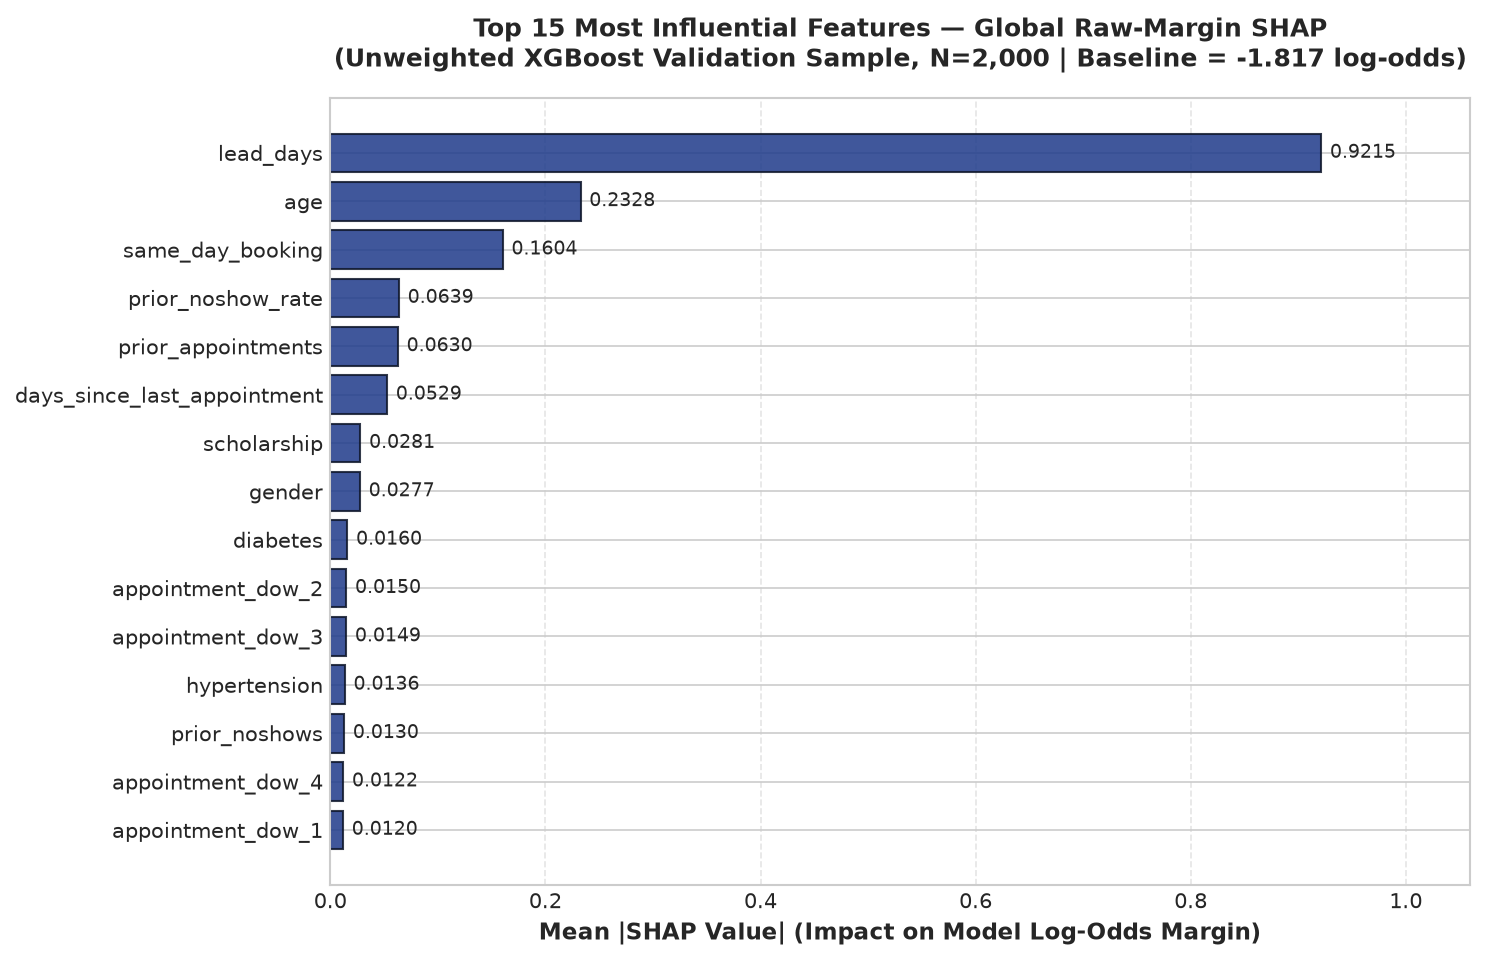

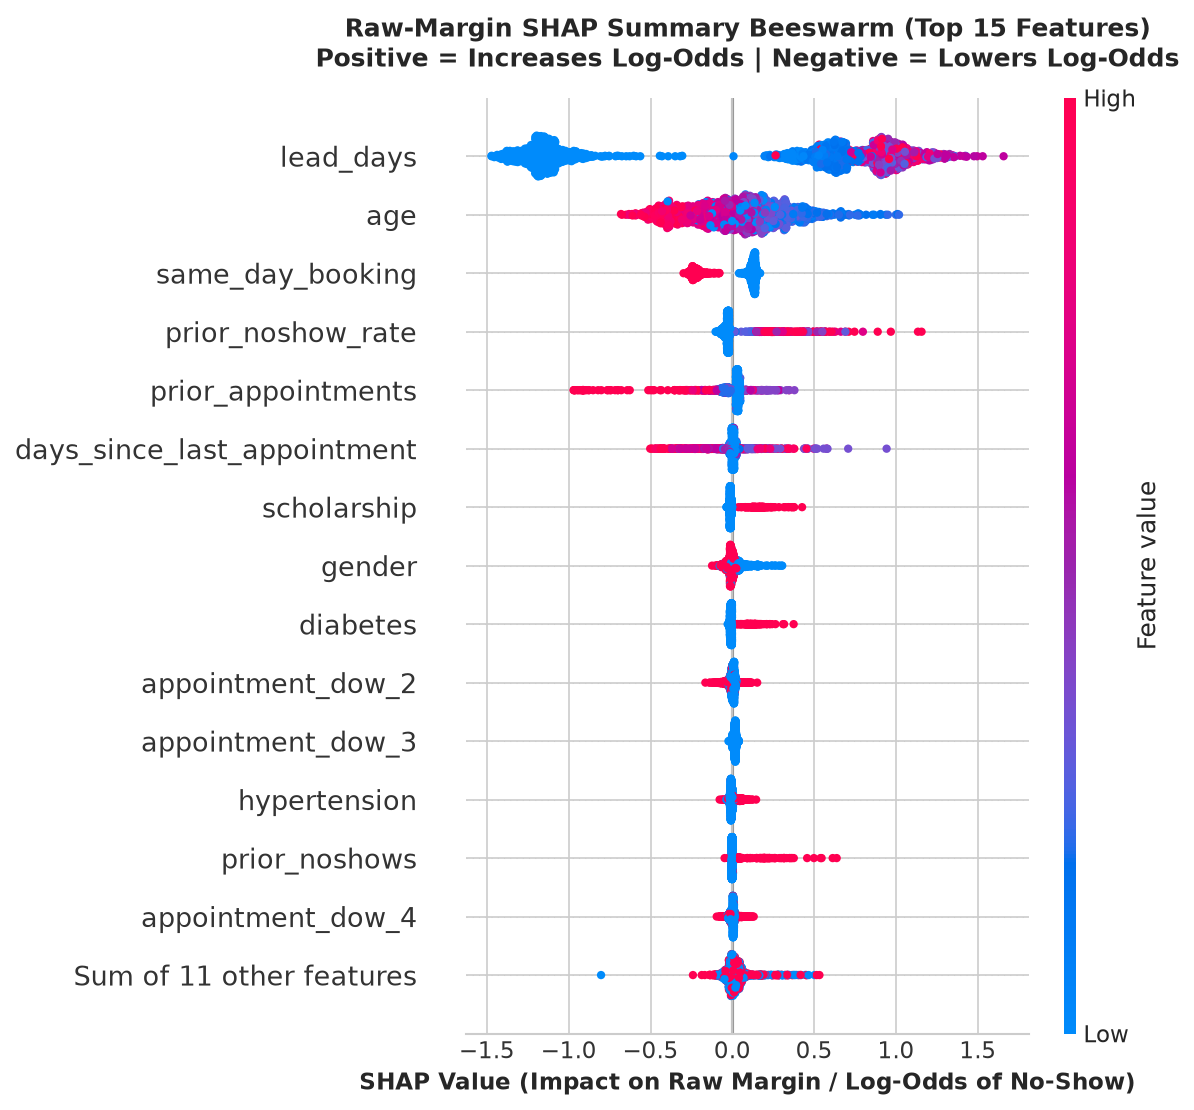

<Figure size 1350x780 with 0 Axes>

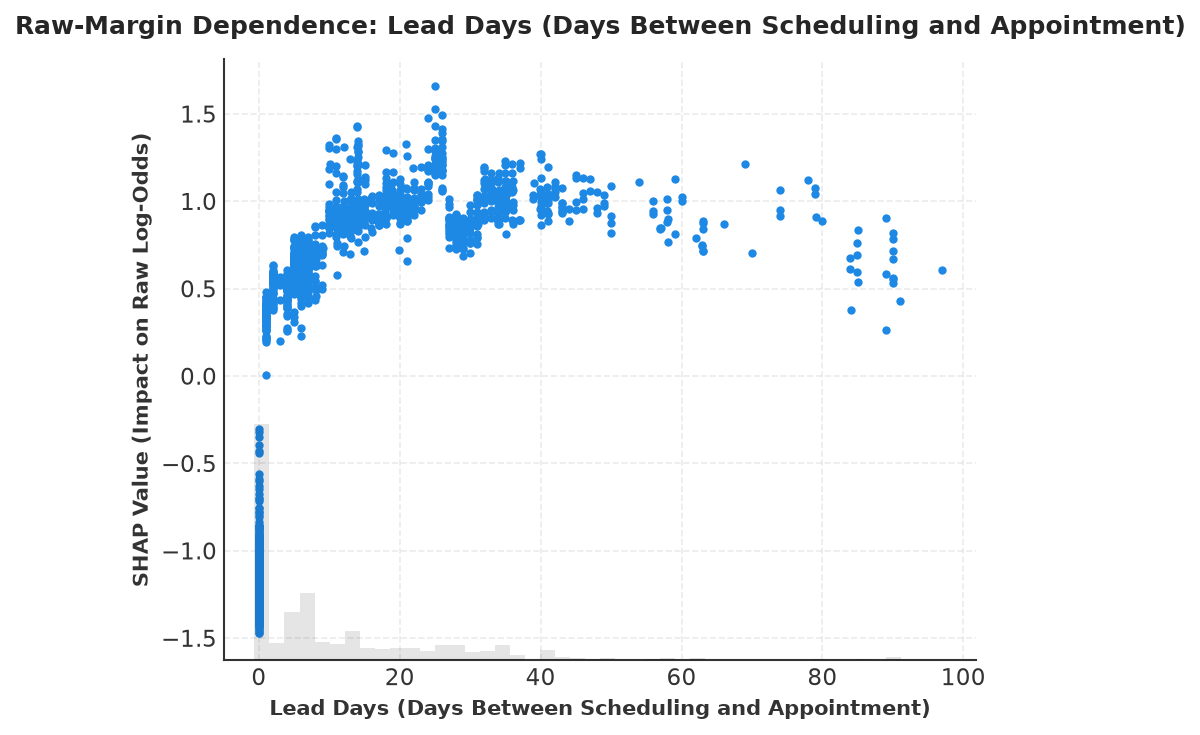

<Figure size 1350x780 with 0 Axes>

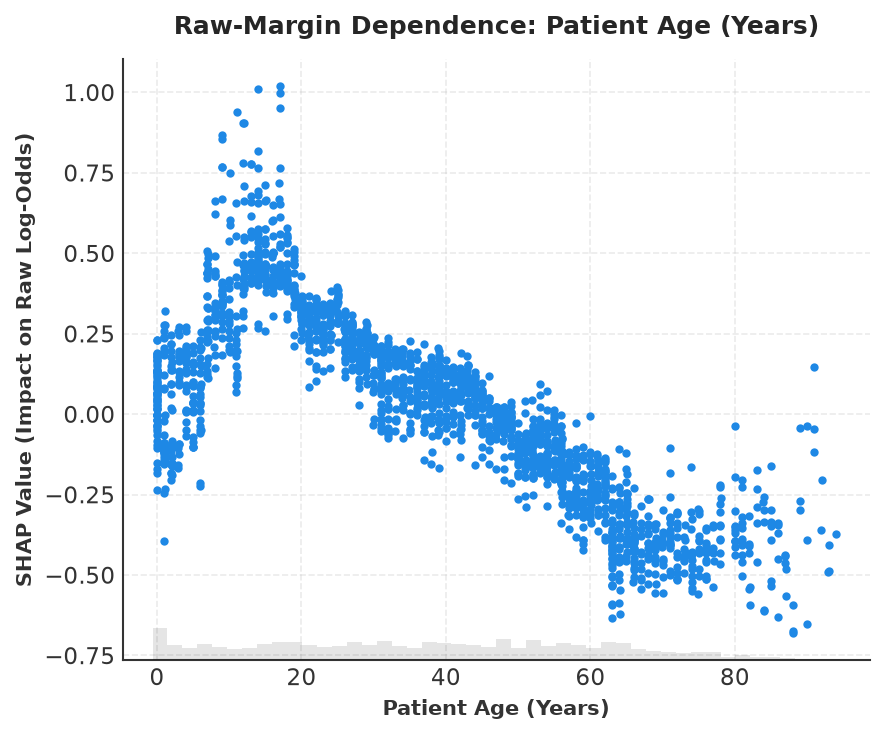

<Figure size 1350x780 with 0 Axes>

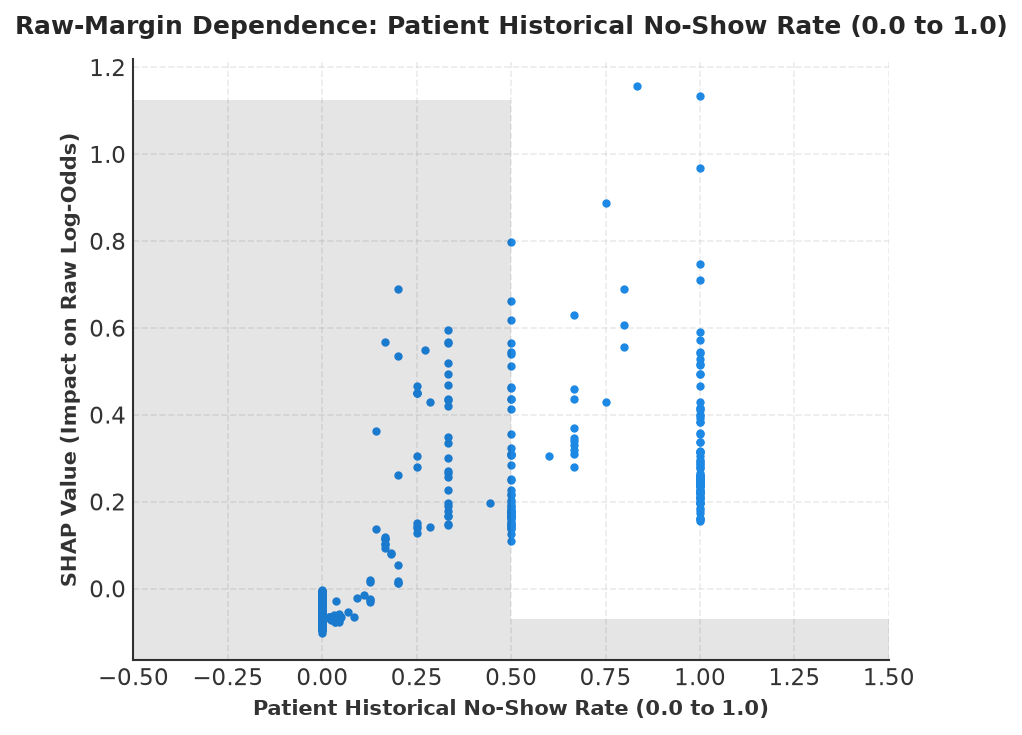

<Figure size 1350x780 with 0 Axes>

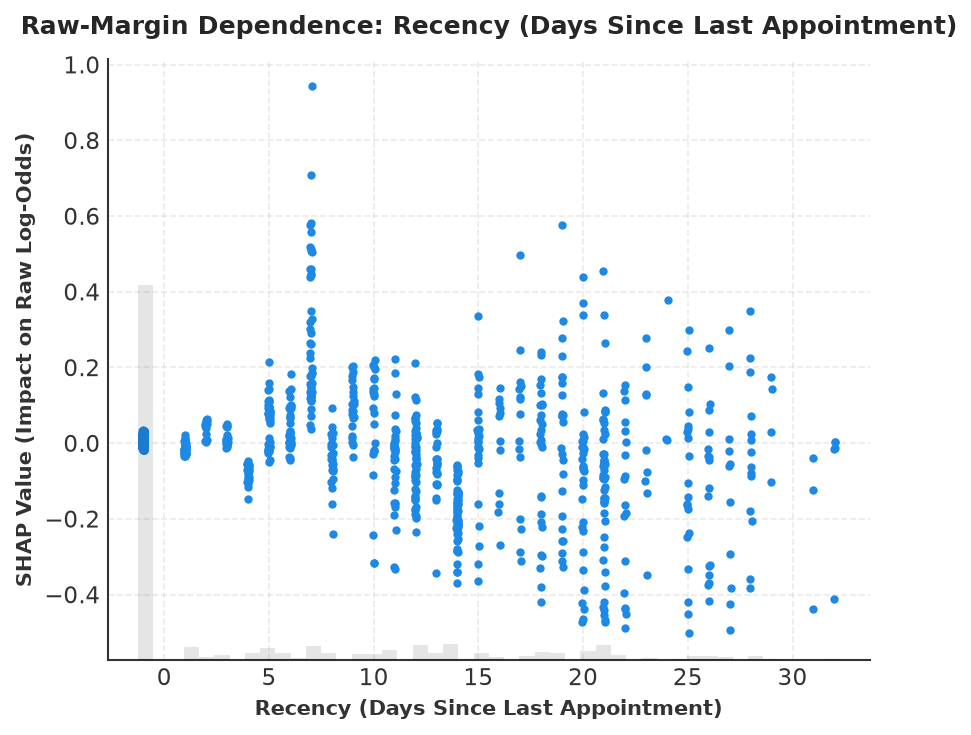

In [5]:
# Render and Save Raw-Margin Figures
# 1. Bar Chart
top15_raw = df_raw_trans_imp.head(15).iloc[::-1]
plt.figure(figsize=(10, 6.5))
bars = plt.barh(top15_raw['clean_name'], top15_raw['mean_abs_shap'], color='#1e3a8a', edgecolor='#0f172a', alpha=0.85)
plt.xlabel('Mean |SHAP Value| (Impact on Model Log-Odds Margin)', fontsize=11, fontweight='bold')
plt.title(f'Top 15 Most Influential Features — Global Raw-Margin SHAP\n(Unweighted XGBoost Validation Sample, N=2,000 | Baseline = {base_val_raw:.3f} log-odds)',
          fontsize=12, fontweight='bold', pad=15)
plt.grid(axis='x', linestyle='--', alpha=0.5)
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.008, bar.get_y() + bar.get_height() / 2, f"{w:.4f}", ha='left', va='center', fontsize=9)
plt.xlim(0, max(top15_raw['mean_abs_shap']) * 1.15)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'shap_bar_importance.png'), dpi=300)
plt.show()

# 2. Beeswarm Plot
plt.figure(figsize=(11, 7.5))
shap.plots.beeswarm(exp_raw_pos, max_display=15, show=False)
plt.title('Raw-Margin SHAP Summary Beeswarm (Top 15 Features)\nPositive = Increases Log-Odds | Negative = Lowers Log-Odds',
          fontsize=12, fontweight='bold', pad=15)
plt.xlabel('SHAP Value (Impact on Raw Margin / Log-Odds of No-Show)', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'shap_beeswarm_summary.png'), dpi=300)
plt.show()

# 3. Dependence Plots (4 Key Predictors)
dep_features = [
    ('lead_days', 'Lead Days (Days Between Scheduling and Appointment)'),
    ('age', 'Patient Age (Years)'),
    ('prior_noshow_rate', 'Patient Historical No-Show Rate (0.0 to 1.0)'),
    ('days_since_last_appointment', 'Recency (Days Since Last Appointment)')
]
for feat_name, feat_label in dep_features:
    if feat_name in clean_names:
        plt.figure(figsize=(9, 5.2))
        shap.plots.scatter(exp_raw_pos[:, feat_name], show=False)
        plt.title(f'Raw-Margin Dependence: {feat_label}', fontsize=12, fontweight='bold', pad=12)
        plt.xlabel(feat_label, fontsize=10, fontweight='bold')
        plt.ylabel('SHAP Value (Impact on Raw Log-Odds)', fontsize=10, fontweight='bold')
        plt.grid(True, linestyle='--', alpha=0.4)
        plt.tight_layout()
        plt.savefig(os.path.join(FIGURES_DIR, f'shap_dependence_{feat_name}.png'), dpi=300)
        plt.show()

### 5. Primary Stakeholder Interpretation: Probability-Space SHAP

#### Methodology & Mathematical Foundations:
1. **Why a Background Dataset is Required:**
   TreeExplainer with `feature_perturbation='interventional'` integrates over an empirical background dataset to evaluate feature contributions in probability space, breaking correlation dependencies.
2. **Exclusively Training-Derived Reference:**
   The 200 background appointments are drawn exclusively from `train_features.csv` (Seed=42), guaranteeing zero contamination of the validation or June evaluation periods.
3. **Effective Background Verification:**
   SHAP's default `max_samples=100` deterministically selects 100 observations from the supplied 200 rows. We confirm that both raw-margin and probability-space explainers use the **identical 100 effective background rows**.
4. **Clinical Interpretation of Baseline Probability:**
   The baseline probability $E[f(X)]$ represents the model's expected no-show probability across the representative background population. It is **not** clinic-wide prevalence or the real-world risk of an average patient.
5. **Direct Probability Additivity:**
   $$P(\text{no-show} \mid x) = \phi_0 + \sum_{i=1}^{n} \phi_i$$
   Every patient's prediction starts at the baseline $\phi_0$. A feature contribution of $+0.10$ adds $+10.0$ percentage points to predicted risk; a contribution of $-0.05$ lowers risk by $5.0$ percentage points.

In [6]:
# 1. Configure interventional TreeExplainer with training background directly
explainer_prob = shap.TreeExplainer(
    clf,
    data=X_bg_trans,
    model_output='probability',
    feature_perturbation='interventional'
)

# 2. Verify identical effective background dataset between explainers
eff_raw_len = explainer_raw.data.shape[0]
eff_prob_len = explainer_prob.data.shape[0]
assert eff_raw_len == 100, f"Expected 100 raw background rows, got {eff_raw_len}"
assert eff_prob_len == 100, f"Expected 100 prob background rows, got {eff_prob_len}"
assert np.array_equal(explainer_raw.data, explainer_prob.data), "Explainers use different effective background datasets!"
print(f"Effective Background Verification: PASSED (Identical {eff_prob_len} rows across Raw and Prob explainers)")

# 3. Compute probability-space explanations for validation sample
shap_obj_prob = explainer_prob(X_val_trans)

# Base value extraction (probability space)
if isinstance(explainer_prob.expected_value, (list, np.ndarray)):
    base_val_prob = float(explainer_prob.expected_value[1] if len(explainer_prob.expected_value) > 1 else explainer_prob.expected_value[0])
elif hasattr(shap_obj_prob, 'base_values'):
    bv = shap_obj_prob.base_values
    base_val_prob = float(bv[0, 1] if len(bv.shape) > 1 and bv.shape[1] > 1 else (bv[0] if len(bv.shape) > 0 else bv))
else:
    base_val_prob = float(explainer_prob.expected_value)

shap_vals_prob_pos = shap_obj_prob.values[:, :, 1] if len(shap_obj_prob.values.shape) == 3 else shap_obj_prob.values

# 4. MANDATORY ADDITIVITY ASSERTION: reconstructed probability == model probability
reconstructed_probs = base_val_prob + np.sum(shap_vals_prob_pos, axis=1)
prob_reconstruction_diff = np.abs(reconstructed_probs - sample_fresh_probs)
max_prob_additivity_err = float(np.max(prob_reconstruction_diff))
mean_prob_additivity_err = float(np.mean(prob_reconstruction_diff))

print(f"SHAP Baseline Probability E[f(X)]:        {base_val_prob * 100:.2f}% ({base_val_prob:.5f})")
print(f"Maximum Absolute Reconstruction Error:    {max_prob_additivity_err:.2e}")
print(f"Mean Absolute Reconstruction Error:       {mean_prob_additivity_err:.2e}")

# Strict technical assertion (< 1e-4 tolerance)
np.testing.assert_allclose(reconstructed_probs, sample_fresh_probs, atol=1e-4)
print(f"Probability Additivity Assertion:         PASSED (Strictly within < 1e-4 tolerance)")

# 5. Construct Class-Specific Probability Explanation Object
exp_prob_pos = shap.Explanation(
    values=shap_vals_prob_pos,
    base_values=np.full(len(val_sample), base_val_prob),
    data=readable_data,
    feature_names=clean_names
)

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


Effective Background Verification: PASSED (Identical 100 rows across Raw and Prob explainers)


 59%|============        | 1189/2000 [00:11<00:07]       

 65%|=============       | 1306/2000 [00:12<00:06]       

 71%|==============      | 1423/2000 [00:13<00:05]       

 77%|===============     | 1547/2000 [00:14<00:04]       

 84%|=================   | 1671/2000 [00:15<00:02]       

 90%|==================  | 1803/2000 [00:16<00:01]       

 97%|=================== | 1931/2000 [00:17<00:00]       

SHAP Baseline Probability E[f(X)]:        18.65% (0.18646)
Maximum Absolute Reconstruction Error:    2.32e-07
Mean Absolute Reconstruction Error:       5.29e-08
Probability Additivity Assertion:         PASSED (Strictly within < 1e-4 tolerance)


### 6. Probability-Space Global Feature Importance

#### Grouped Conceptual Feature Aggregation:
For one-hot encoded categorical features (such as days of the week), we sum their individual SHAP probability contributions per patient $\phi_{i, \text{orig}} = \sum_{j \in \text{orig}} \phi_{i, j}$ **before** computing the mean absolute value across the cohort:
$$\text{Grouped Importance} = \frac{1}{N} \sum_{i=1}^{N} \left| \sum_{j \in \text{orig}} \phi_{i, j} \right|$$

This accurately measures each conceptual feature's impact on no-show probability without diluting multi-column dummy variables.
- **Mean Absolute SHAP (% pts):** Average magnitude of impact on probability.
- **Mean Signed SHAP (% pts):** Directional tendency across the cohort.

Saved Grouped CSV: C:\Users\gaura\Downloads\PATIENT CURN PRIDICTION\data\processed\shap_probability_grouped_feature_importance.csv

Top 10 Grouped Features (Mean Absolute Impact in Probability & Percentage Points):


,rank,original_feature,mean_abs_shap_pct,mean_abs_shap_prob,mean_signed_shap_pct
0,1,lead_days,10.786493,0.107865,2.105208
1,2,age,3.278304,0.032783,0.511671
2,3,same_day_booking,1.766820,0.017668,0.084305
3,4,prior_noshow_rate,0.756304,0.007563,0.118906
4,5,prior_appointments,0.700370,0.007004,-0.072671
5,6,days_since_last_appointment,0.618794,0.006188,0.106231
6,7,appointment_dow,0.477149,0.004771,0.204815
7,8,scholarship,0.423293,0.004233,0.081418
8,9,scheduled_dow,0.323165,0.003232,0.066597
9,10,gender,0.302247,0.003022,0.078730


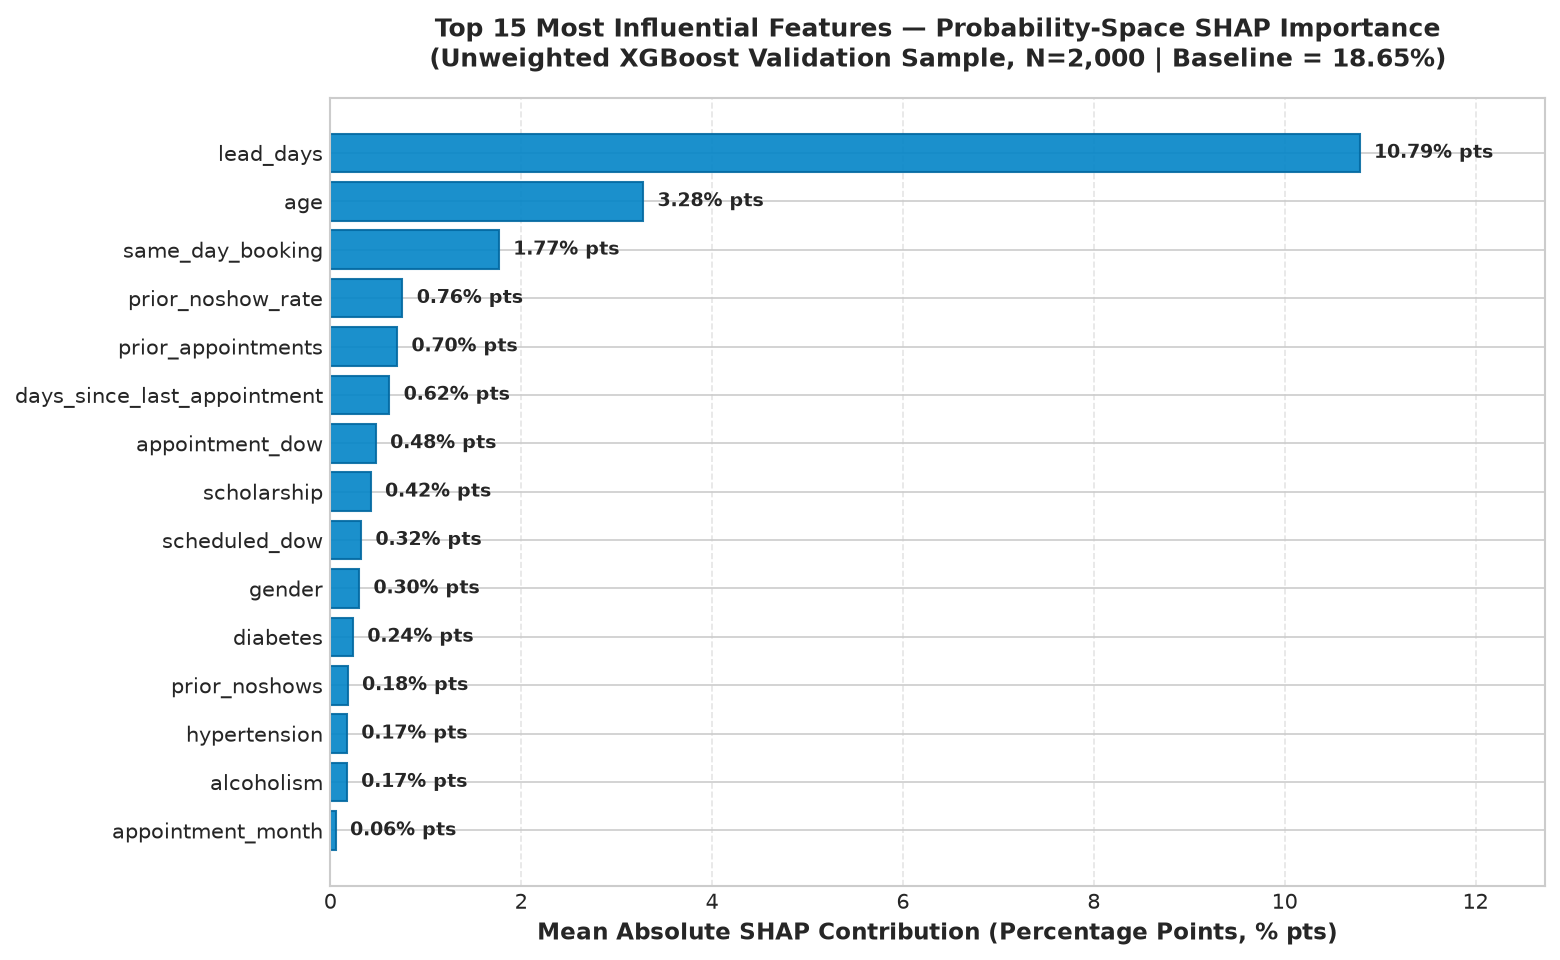

In [7]:
# 1. Transformed-level importance
mean_abs_prob_trans = np.mean(np.abs(shap_vals_prob_pos), axis=0)
df_prob_trans_imp = pd.DataFrame({
    'transformed_feature': feature_names_out,
    'clean_name': clean_names,
    'original_feature': [col_to_orig[c] for c in feature_names_out],
    'mean_abs_shap_prob': mean_abs_prob_trans,
    'mean_abs_shap_pct': mean_abs_prob_trans * 100.0,
    'mean_signed_shap_prob': np.mean(shap_vals_prob_pos, axis=0),
    'mean_signed_shap_pct': np.mean(shap_vals_prob_pos, axis=0) * 100.0
}).sort_values('mean_abs_shap_prob', ascending=False).reset_index(drop=True)
df_prob_trans_imp['rank'] = df_prob_trans_imp.index + 1
df_prob_trans_imp.to_csv(OUTPUT_PROB_TRANS_CSV, index=False)

# 2. Grouped original feature importance (probability space)
grouped_prob_records = []
for orig in approved_features:
    cols_idx = [i for i, col in enumerate(feature_names_out) if col_to_orig[col] == orig]
    if cols_idx:
        obs_contrib = np.sum(shap_vals_prob_pos[:, cols_idx], axis=1)
        mean_abs_p = float(np.mean(np.abs(obs_contrib)))
        mean_signed_p = float(np.mean(obs_contrib))
        grouped_prob_records.append({
            'original_feature': orig,
            'mean_abs_shap_prob': mean_abs_p,
            'mean_abs_shap_pct': mean_abs_p * 100.0,
            'mean_signed_shap_prob': mean_signed_p,
            'mean_signed_shap_pct': mean_signed_p * 100.0
        })

df_prob_grouped_imp = pd.DataFrame(grouped_prob_records).sort_values('mean_abs_shap_prob', ascending=False).reset_index(drop=True)
df_prob_grouped_imp['rank'] = df_prob_grouped_imp.index + 1
df_prob_grouped_imp.to_csv(OUTPUT_PROB_GROUPED_CSV, index=False)

print(f"Saved Grouped CSV: {OUTPUT_PROB_GROUPED_CSV}")
print("\nTop 10 Grouped Features (Mean Absolute Impact in Probability & Percentage Points):")
display(df_prob_grouped_imp.head(10)[['rank', 'original_feature', 'mean_abs_shap_pct', 'mean_abs_shap_prob', 'mean_signed_shap_pct']])

# 3. Horizontal Bar Chart in Percentage Points (% pts)
top15_prob = df_prob_grouped_imp.head(15).iloc[::-1]
plt.figure(figsize=(10.5, 6.5))
bars = plt.barh(top15_prob['original_feature'], top15_prob['mean_abs_shap_pct'], color='#0284c7', edgecolor='#0369a1', alpha=0.9)
plt.xlabel('Mean Absolute SHAP Contribution (Percentage Points, % pts)', fontsize=11, fontweight='bold')
plt.title(f'Top 15 Most Influential Features — Probability-Space SHAP Importance\n(Unweighted XGBoost Validation Sample, N=2,000 | Baseline = {base_val_prob*100:.2f}%)',
          fontsize=12, fontweight='bold', pad=15)
plt.grid(axis='x', linestyle='--', alpha=0.5)
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.15, bar.get_y() + bar.get_height() / 2, f"{w:.2f}% pts", ha='left', va='center', fontsize=9, fontweight='bold')
plt.xlim(0, max(top15_prob['mean_abs_shap_pct']) * 1.18)
plt.tight_layout()
bar_prob_path = os.path.join(FIGURES_DIR, 'shap_prob_bar_importance.png')
plt.savefig(bar_prob_path, dpi=300)
plt.show()

### 7. Probability-Space Beeswarm Summary Plot

The probability beeswarm plot visualizes the spread and directionality of feature impacts directly in **probability units**:
- **Right of 0.0 ($> 0$):** Points push patient no-show risk above baseline.
- **Left of 0.0 ($< 0$):** Points reduce patient no-show risk below baseline.

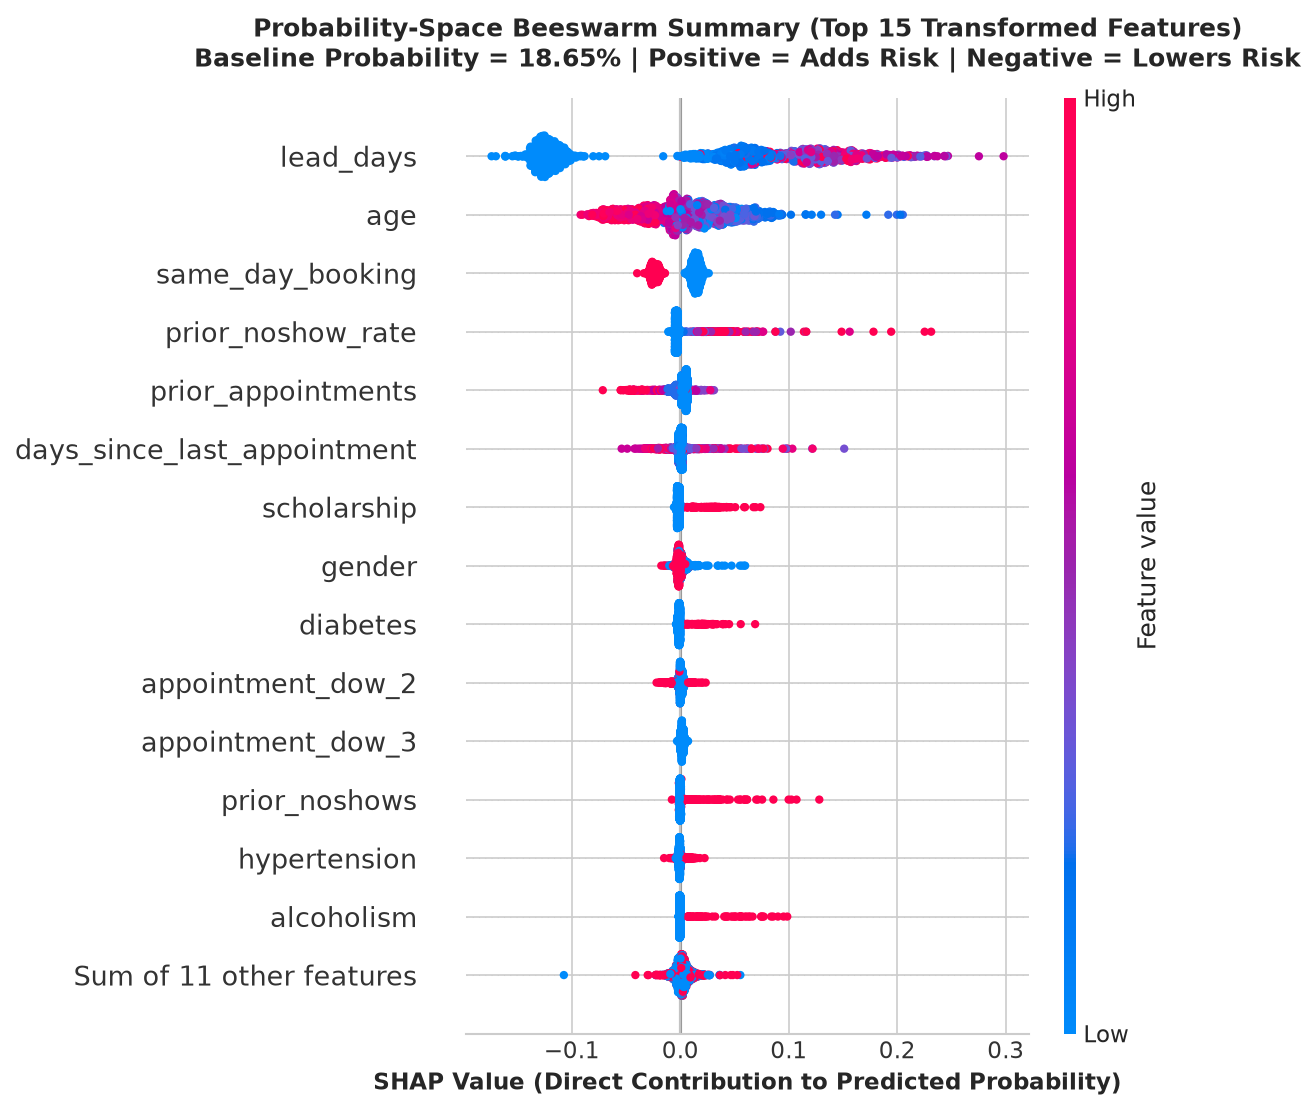

EMPIRICAL PROBABILITY SHIFTS DERIVED FROM VALIDATION COHORT:
1. Same-Day Appointments (lead_days == 0) Average Contribution: -12.22% pts (Suppresses risk)
   Appointments > 14 Lead Days Average Contribution:           +13.76% pts (Increases risk)
2. Patients Age < 35 Average Age Contribution:                  +3.63% pts
   Patients Age > 60 Average Age Contribution:                  -4.97% pts (Protective adherence)
3. Zero Prior Missed Visits Average History Contribution:       -0.36% pts
   Non-Zero Prior Missed Visits Average History Contribution:   +3.63% pts (Risk multiplier)


In [8]:
plt.figure(figsize=(11, 7.5))
shap.plots.beeswarm(exp_prob_pos, max_display=15, show=False)
plt.title(f'Probability-Space Beeswarm Summary (Top 15 Transformed Features)\nBaseline Probability = {base_val_prob*100:.2f}% | Positive = Adds Risk | Negative = Lowers Risk',
          fontsize=12, fontweight='bold', pad=15)
plt.xlabel('SHAP Value (Direct Contribution to Predicted Probability)', fontsize=11, fontweight='bold')
plt.tight_layout()
beeswarm_prob_path = os.path.join(FIGURES_DIR, 'shap_prob_beeswarm_summary.png')
plt.savefig(beeswarm_prob_path, dpi=300)
plt.show()

# Dynamically compute empirical probability shifts from executed data
ld_col = clean_names.index('lead_days')
age_col = clean_names.index('age')
pnr_col = clean_names.index('prior_noshow_rate')

print("=" * 75)
print("EMPIRICAL PROBABILITY SHIFTS DERIVED FROM VALIDATION COHORT:")
print("=" * 75)
print(f"1. Same-Day Appointments (lead_days == 0) Average Contribution: {np.mean(shap_vals_prob_pos[val_sample['lead_days'] == 0, ld_col])*100:+.2f}% pts (Suppresses risk)")
print(f"   Appointments > 14 Lead Days Average Contribution:           {np.mean(shap_vals_prob_pos[val_sample['lead_days'] > 14, ld_col])*100:+.2f}% pts (Increases risk)")
print(f"2. Patients Age < 35 Average Age Contribution:                  {np.mean(shap_vals_prob_pos[val_sample['age'] < 35, age_col])*100:+.2f}% pts")
print(f"   Patients Age > 60 Average Age Contribution:                  {np.mean(shap_vals_prob_pos[val_sample['age'] > 60, age_col])*100:+.2f}% pts (Protective adherence)")
print(f"3. Zero Prior Missed Visits Average History Contribution:       {np.mean(shap_vals_prob_pos[val_sample['prior_noshow_rate'] == 0, pnr_col])*100:+.2f}% pts")
print(f"   Non-Zero Prior Missed Visits Average History Contribution:   {np.mean(shap_vals_prob_pos[val_sample['prior_noshow_rate'] > 0, pnr_col])*100:+.2f}% pts (Risk multiplier)")
print("=" * 75)

### 8. Probability-Space Feature Dependence Plots

Dependence plots demonstrate non-linear probability thresholds across key clinical and operational predictors. The vertical axis directly quantifies the **probability shift** associated with each feature value.

<Figure size 1350x780 with 0 Axes>

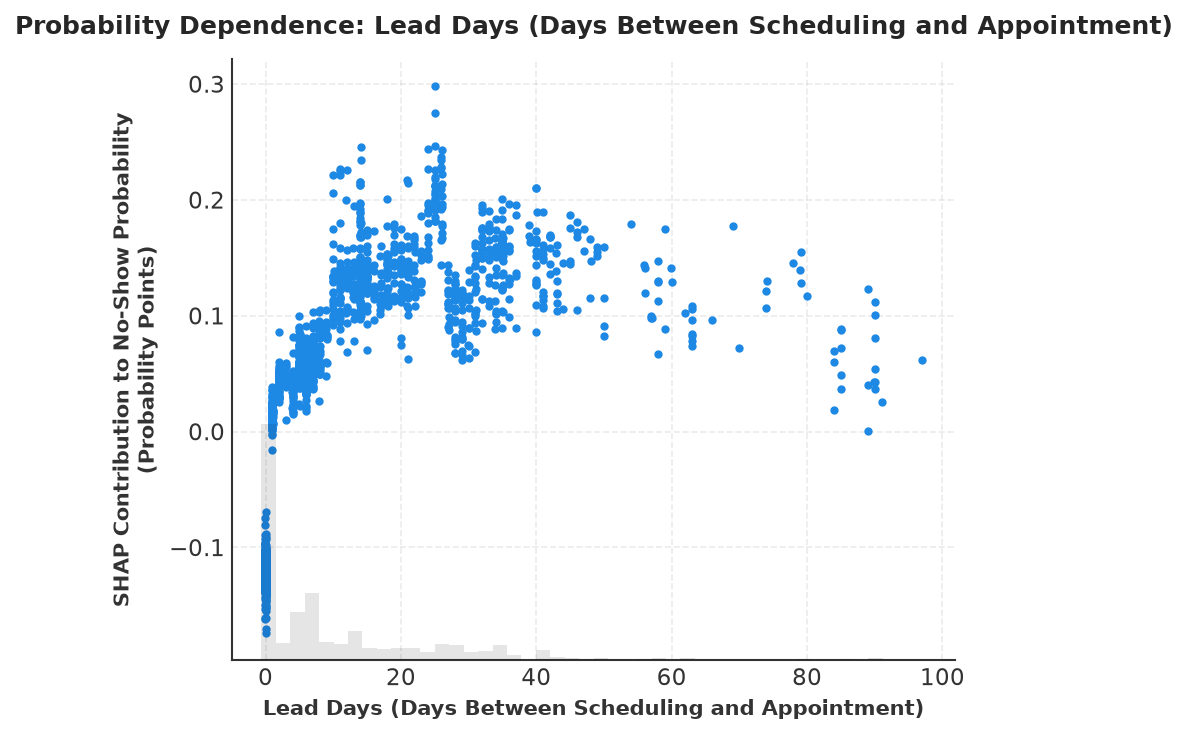

<Figure size 1350x780 with 0 Axes>

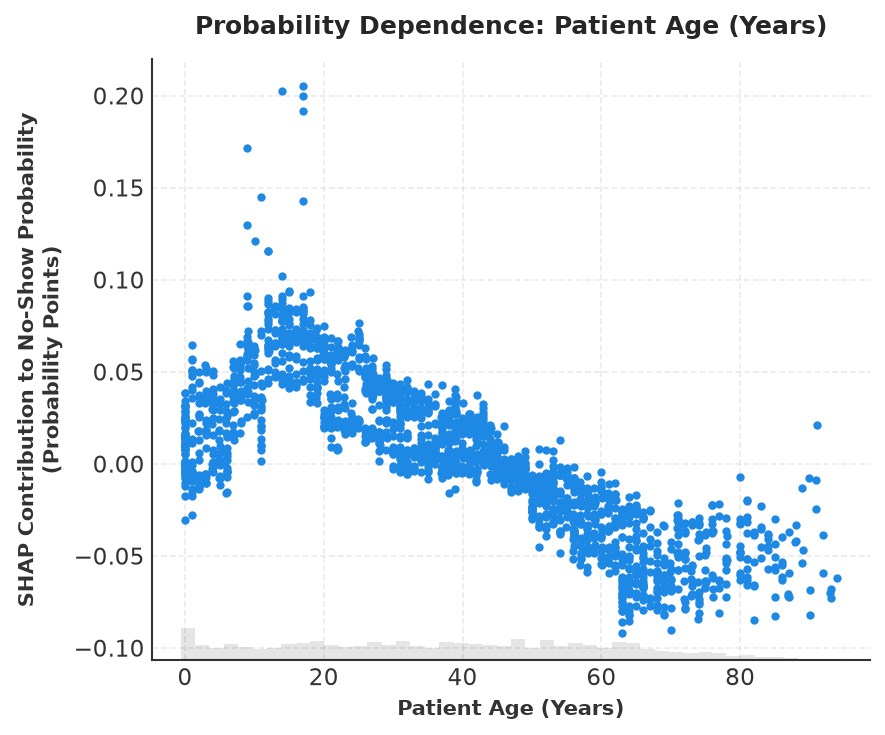

<Figure size 1350x780 with 0 Axes>

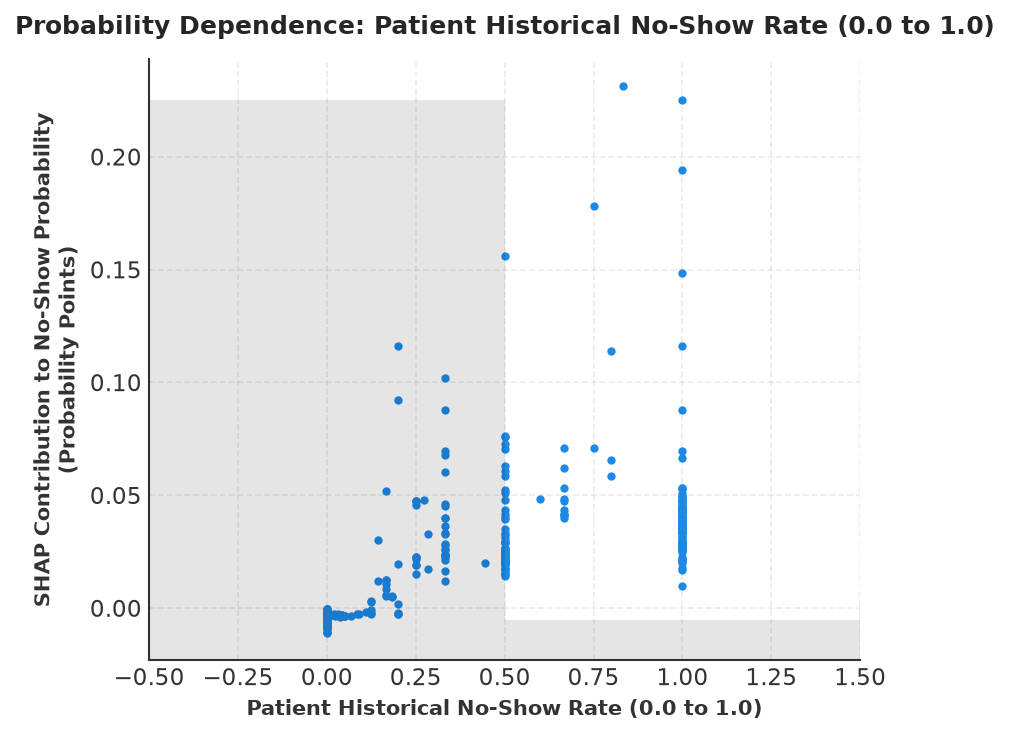

<Figure size 1350x780 with 0 Axes>

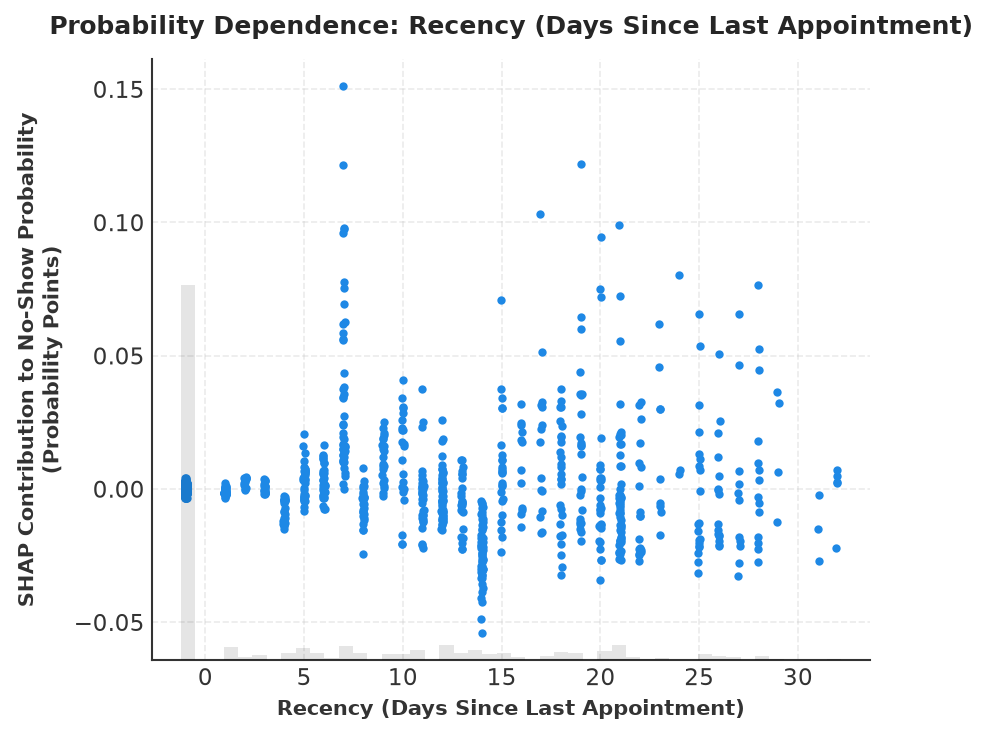

In [9]:
for feat_name, feat_label in dep_features:
    if feat_name in clean_names:
        plt.figure(figsize=(9, 5.2))
        shap.plots.scatter(exp_prob_pos[:, feat_name], show=False)
        plt.title(f'Probability Dependence: {feat_label}', fontsize=12, fontweight='bold', pad=12)
        plt.xlabel(feat_label, fontsize=10, fontweight='bold')
        plt.ylabel('SHAP Contribution to No-Show Probability\n(Probability Points)', fontsize=10, fontweight='bold')
        plt.grid(True, linestyle='--', alpha=0.4)
        plt.tight_layout()
        dep_fig_path = os.path.join(FIGURES_DIR, f'shap_prob_dependence_{feat_name}.png')
        plt.savefig(dep_fig_path, dpi=300)
        plt.show()

### 9. Local Waterfall Explanations & Error Analysis

Each waterfall plot begins at the empirical training baseline probability $\phi_0 = E[f(X)]$ and sequentially applies individual feature contributions (positive additions in red, negative reductions in blue) to reconstruct the exact predicted positive-class probability.

#### Three Deterministically Selected Validation Cases:
1. **Case 1 (High Risk):** Correctly predicted no-show ($p \ge 0.70$, Actual: 1).
2. **Case 2 (Low Risk):** Correctly predicted attendee ($p \le 0.05$, Actual: 0).
3. **Case 3 (Error Case):** Boundary case under the business-tuned decision threshold of $0.15$ (preferring False Positive, else False Negative).


Case 1: High Risk Patient (Correctly Identified No-Show)
Sample Row: 361 | Actual: No-Show (1) | Predicted: 76.84% | Baseline: 18.65%
Reconstructed Probability: 76.84% (Error = 1.27e-07)
Key Feature Values & Contributions (% pts):
  prior_noshow_rate            = 1.0    | Contribution: +22.53% pts
  age                          = 17     | Contribution: +19.96% pts
  prior_noshows                = 4      | Contribution: +10.71% pts
  lead_days                    = 0      | Contribution: -6.92% pts
  days_since_last_appointment  = 7      | Contribution: +6.27% pts
  gender                       = 0      | Contribution: +5.88% pts


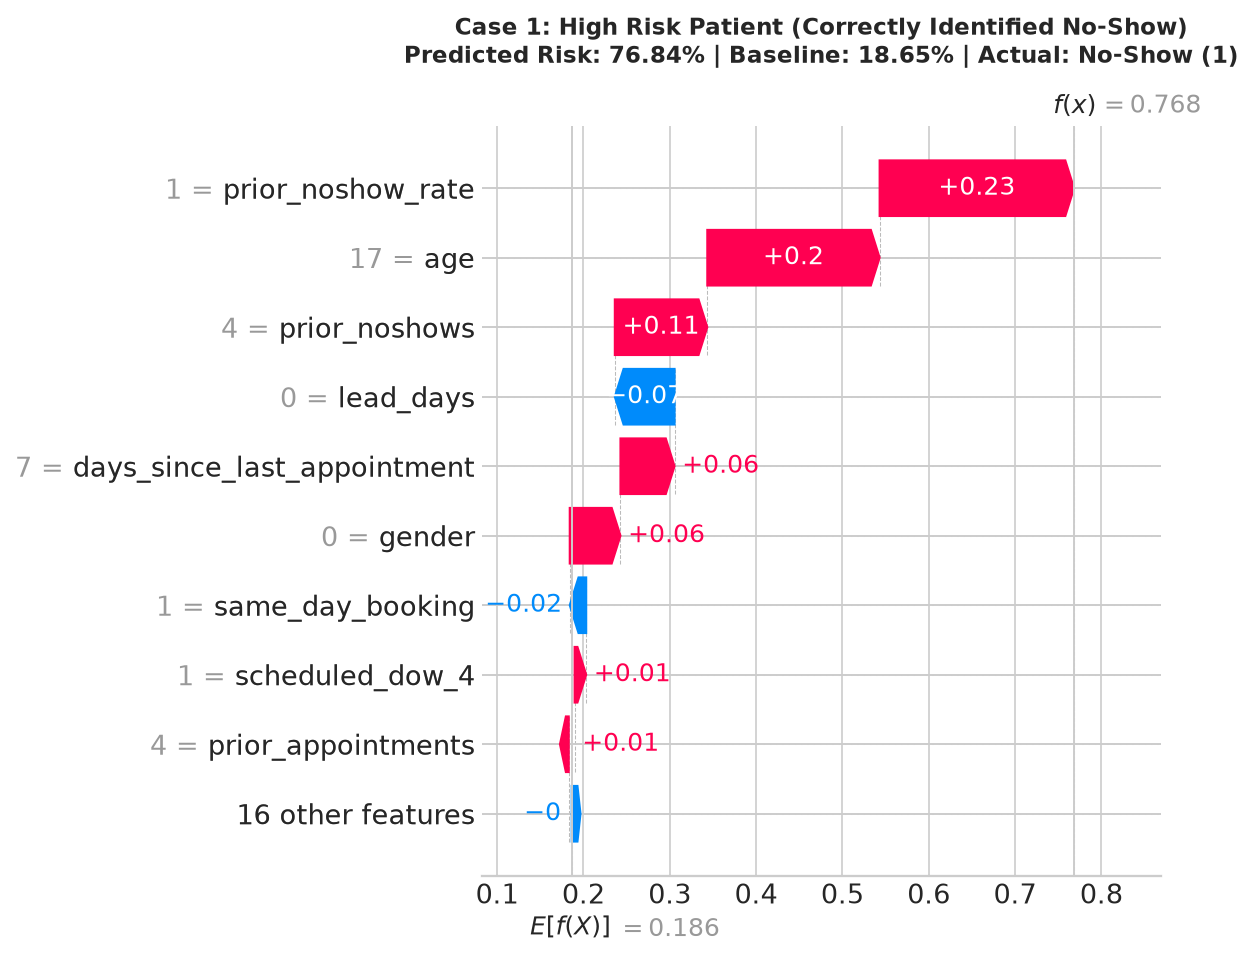


Case 2: Low Risk Patient (Correctly Identified Show-Up)
Sample Row: 714 | Actual: Show-Up (0) | Predicted: 0.66% | Baseline: 18.65%
Reconstructed Probability: 0.66% (Error = 8.67e-09)
Key Feature Values & Contributions (% pts):
  lead_days                    = 0      | Contribution: -8.94% pts
  prior_appointments           = 40     | Contribution: -4.20% pts
  age                          = 63     | Contribution: -2.87% pts
  same_day_booking             = 1      | Contribution: -1.49% pts
  alcoholism                   = 1      | Contribution: +0.73% pts
  gender                       = 0      | Contribution: -0.47% pts


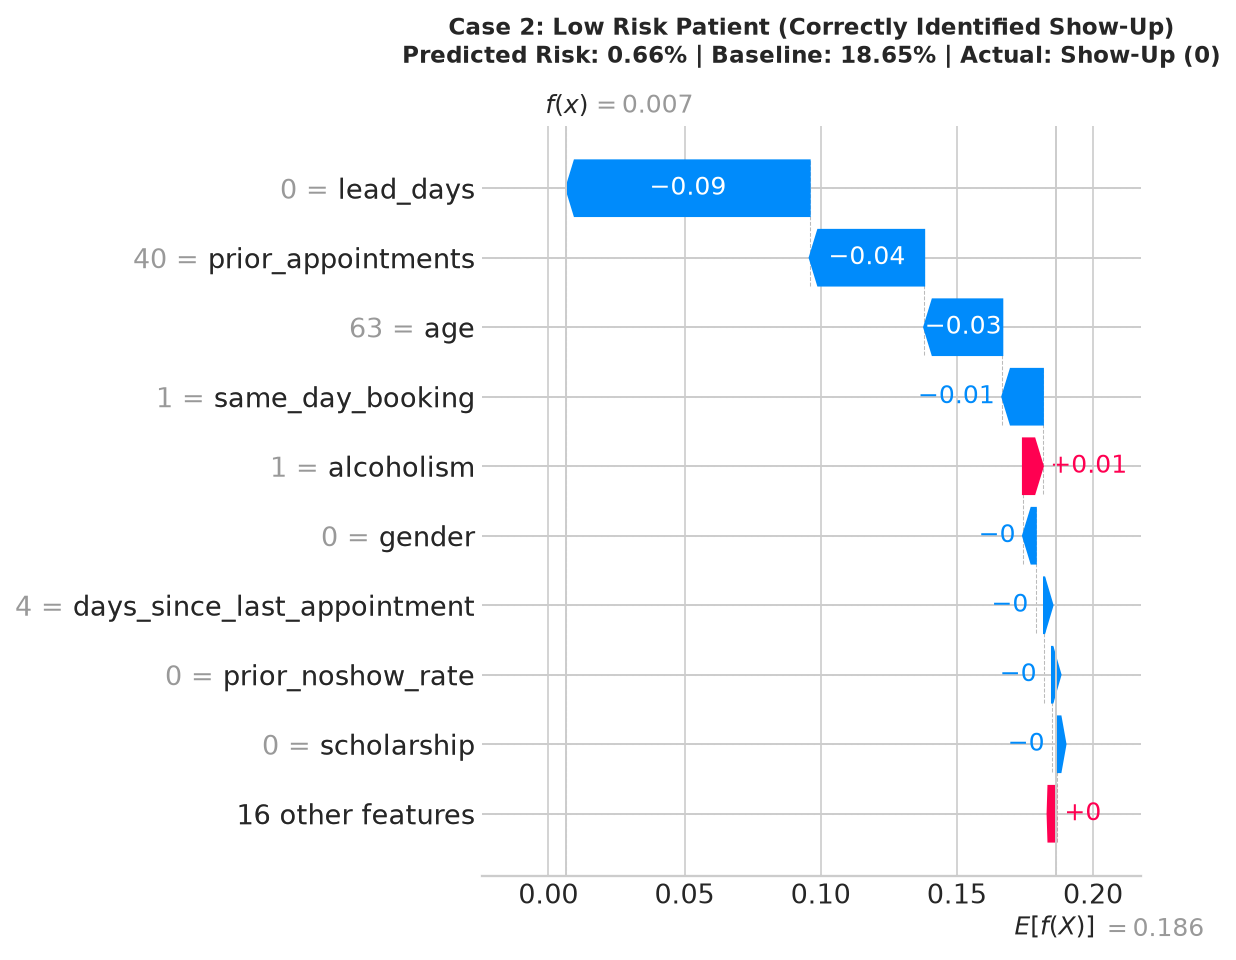


Case 3: Error Case [False Positive (p >= 0.15, Actual = 0)]
Sample Row: 1110 | Actual: Show-Up (0) | Predicted: 66.01% | Baseline: 18.65%
Reconstructed Probability: 66.01% (Error = 2.74e-08)
Key Feature Values & Contributions (% pts):
  prior_noshow_rate            = 1.0    | Contribution: +19.44% pts
  age                          = 17     | Contribution: +19.17% pts
  prior_noshows                = 4      | Contribution: +12.81% pts
  lead_days                    = 0      | Contribution: -10.07% pts
  gender                       = 0      | Contribution: +5.98% pts
  same_day_booking             = 1      | Contribution: -1.84% pts


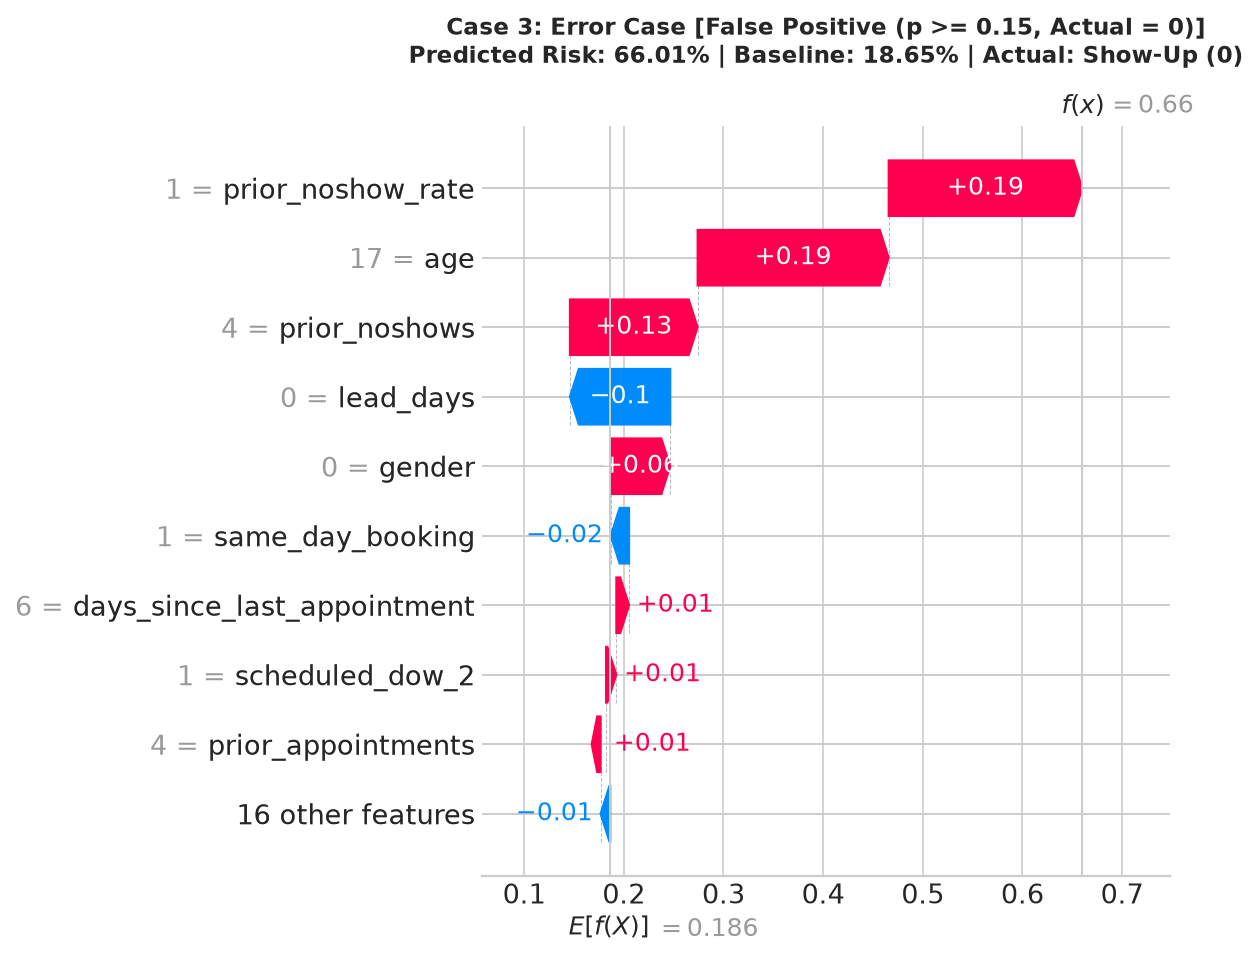

Saved Local Explanations CSV: C:\Users\gaura\Downloads\PATIENT CURN PRIDICTION\data\processed\shap_probability_local_explanations.csv


In [10]:
# 1. Deterministic case selection
high_cand = val_sample[(val_sample['pred_prob'] >= 0.70) & (val_sample['no_show'] == 1)]
if len(high_cand) > 0:
    high_idx = int(high_cand.sort_values('pred_prob', ascending=False).index[0])
else:
    high_cand = val_sample[val_sample['no_show'] == 1]
    high_idx = int(high_cand.sort_values('pred_prob', ascending=False).index[0])

low_cand = val_sample[(val_sample['pred_prob'] <= 0.05) & (val_sample['no_show'] == 0)]
if len(low_cand) > 0:
    low_idx = int(low_cand.sort_values('pred_prob', ascending=True).index[0])
else:
    low_cand = val_sample[val_sample['no_show'] == 0]
    low_idx = int(low_cand.sort_values('pred_prob', ascending=True).index[0])

fp_cand = val_sample[(val_sample['pred_prob'] >= 0.15) & (val_sample['no_show'] == 0)]
fn_cand = val_sample[(val_sample['pred_prob'] < 0.15) & (val_sample['no_show'] == 1)]
if len(fp_cand) > 0:
    err_idx = int(fp_cand.sort_values('pred_prob', ascending=False).index[0])
    err_type = 'False Positive (p >= 0.15, Actual = 0)'
elif len(fn_cand) > 0:
    err_idx = int(fn_cand.sort_values('pred_prob', ascending=True).index[0])
    err_type = 'False Negative (p < 0.15, Actual = 1)'
else:
    diffs = (val_sample['pred_prob'] - 0.15).abs()
    err_idx = int(diffs.sort_values().index[0])
    err_type = 'Boundary Case (|p - 0.15| minimum)'

selected_cases = [
    ('high_risk', high_idx, 'Case 1: High Risk Patient (Correctly Identified No-Show)'),
    ('low_risk', low_idx, 'Case 2: Low Risk Patient (Correctly Identified Show-Up)'),
    ('error_case', err_idx, f'Case 3: Error Case [{err_type}]')
]

# 2. Export local explanations CSV & Render Waterfall Plots
local_rows = []
for c_key, s_idx, c_title in selected_cases:
    row_data = val_sample.iloc[s_idx]
    actual_label = "No-Show (1)" if row_data['no_show'] == 1 else "Show-Up (0)"
    p_val = float(row_data['pred_prob'])
    sv_row = shap_vals_prob_pos[s_idx]
    rec_p = float(base_val_prob + np.sum(sv_row))
    err = float(np.abs(rec_p - p_val))
    np.testing.assert_allclose(rec_p, p_val, atol=1e-4)

    rec_dict = {
        'case_key': c_key,
        'case_description': c_title,
        'sample_row_index': s_idx,
        'actual_no_show': int(row_data['no_show']),
        'predicted_probability': p_val,
        'predicted_probability_pct': p_val * 100.0,
        'shap_baseline_probability': base_val_prob,
        'shap_baseline_probability_pct': base_val_prob * 100.0,
        'reconstructed_probability': rec_p,
        'reconstructed_probability_pct': rec_p * 100.0,
        'reconstruction_error': err
    }
    for orig in approved_features:
        cols_idx = [i for i, col in enumerate(feature_names_out) if col_to_orig[col] == orig]
        orig_contrib = float(np.sum(sv_row[cols_idx])) if cols_idx else 0.0
        rec_dict[f'shap_prob_{orig}'] = orig_contrib
        rec_dict[f'shap_pct_{orig}'] = orig_contrib * 100.0
    local_rows.append(rec_dict)

    print(f"\n{'='*75}")
    print(f"{c_title}")
    print(f"Sample Row: {s_idx} | Actual: {actual_label} | Predicted: {p_val*100:.2f}% | Baseline: {base_val_prob*100:.2f}%")
    print(f"Reconstructed Probability: {rec_p*100:.2f}% (Error = {err:.2e})")
    print("Key Feature Values & Contributions (% pts):")
    top_indices = np.argsort(np.abs(sv_row))[::-1][:6]
    for tidx in top_indices:
        print(f"  {clean_names[tidx]:<28} = {row_data[col_to_orig[feature_names_out[tidx]]]:<6} | Contribution: {sv_row[tidx]*100:+.2f}% pts")
    print(f"{'='*75}")

    # Probability-Space Waterfall Plot
    plt.figure(figsize=(10.5, 6))
    shap.plots.waterfall(exp_prob_pos[s_idx], max_display=10, show=False)
    plt.title(f"{c_title}\nPredicted Risk: {p_val*100:.2f}% | Baseline: {base_val_prob*100:.2f}% | Actual: {actual_label}",
              fontsize=11, fontweight='bold', pad=15)
    plt.tight_layout()
    wf_path = os.path.join(FIGURES_DIR, f'shap_prob_waterfall_{c_key}.png')
    plt.savefig(wf_path, dpi=300)
    plt.show()

    # Raw-Margin Waterfall Plot
    plt.figure(figsize=(10.5, 6))
    shap.plots.waterfall(exp_raw_pos[s_idx], max_display=10, show=False)
    plt.title(f"{c_title} [Raw Margin]\nPredicted Risk: {p_val*100:.2f}% | Baseline Log-Odds: {base_val_raw:.3f} | Actual: {actual_label}",
              fontsize=11, fontweight='bold', pad=15)
    plt.tight_layout()
    wf_raw_path = os.path.join(FIGURES_DIR, f'shap_waterfall_{c_key}.png')
    plt.savefig(wf_raw_path, dpi=300)
    plt.close()

df_local_exp = pd.DataFrame(local_rows)
df_local_exp.to_csv(OUTPUT_PROB_LOCAL_CSV, index=False)
print(f"Saved Local Explanations CSV: {OUTPUT_PROB_LOCAL_CSV}")

### 10. Governance, Methodological Constraints, & Practical Limitations

#### 1. Attribution vs. Clinical Causality:
SHAP quantifies how features shift the tree ensemble's internal probability calculation. It does **not** model counterfactual clinical interventions. For instance, observing that `lead_days` adds $+10.8\%$ points on average does not prove that arbitrarily rescheduling appointments to shorter windows will cause patients to attend, particularly if their personal schedule or transportation constraints remain unaddressed.

#### 2. Correlated Features and Interventional Masking:
Interventional TreeExplainer marginalizes over independent feature distributions. When predictors are correlated—such as `prior_appointments`, `prior_noshows`, and `prior_noshow_rate`—the masker can theoretically query tree combinations that are uncommon in clinical practice. While our point-in-time feature engineering prevented logical inconsistencies in the data, clinical users must interpret individual historical features in concert rather than in isolation.

#### 3. Baseline Population Sensitivity:
SHAP values measure deviation from the reference background dataset. If the background population changes (e.g., if evaluated against an elderly chronic-care cohort versus a young walk-in clinic cohort), the baseline $\phi_0$ and individual attributions $\phi_i$ will adjust, even if the model's actual predicted probability $f(x)$ remains identical.

#### 4. Equitable Care and Non-Discrimination:
Demographic variables such as `age` and welfare scholarship (`scholarship`) capture social determinants of health. Healthcare protocols must mandate that risk scores are used exclusively to **allocate supportive outreach** (e.g., patient navigation, reminder calls, transportation vouchers) and never to deprioritize or restrict care.

In [11]:
# Final Comprehensive Deliverables Verification Checklist
expected_artifacts = [
    # Technical Reference (Raw Margin, 11 total: 2 CSVs + 9 Figures)
    (OUTPUT_RAW_TRANS_CSV, "Raw Transformed CSV"),
    (OUTPUT_RAW_GROUPED_CSV, "Raw Grouped CSV"),
    (os.path.join(FIGURES_DIR, 'shap_bar_importance.png'), "Raw Bar Chart"),
    (os.path.join(FIGURES_DIR, 'shap_beeswarm_summary.png'), "Raw Beeswarm Plot"),
    (os.path.join(FIGURES_DIR, 'shap_dependence_lead_days.png'), "Raw Dep: Lead Days"),
    (os.path.join(FIGURES_DIR, 'shap_dependence_age.png'), "Raw Dep: Age"),
    (os.path.join(FIGURES_DIR, 'shap_dependence_prior_noshow_rate.png'), "Raw Dep: Prior No-Show Rate"),
    (os.path.join(FIGURES_DIR, 'shap_dependence_days_since_last_appointment.png'), "Raw Dep: Recency"),
    (os.path.join(FIGURES_DIR, 'shap_waterfall_high_risk.png'), "Raw Waterfall: High Risk"),
    (os.path.join(FIGURES_DIR, 'shap_waterfall_low_risk.png'), "Raw Waterfall: Low Risk"),
    (os.path.join(FIGURES_DIR, 'shap_waterfall_error_case.png'), "Raw Waterfall: Error Case"),

    # Primary Stakeholder (Probability Space, 12 total: 3 CSVs + 9 Figures)
    (OUTPUT_PROB_TRANS_CSV, "Prob Transformed CSV"),
    (OUTPUT_PROB_GROUPED_CSV, "Prob Grouped CSV"),
    (OUTPUT_PROB_LOCAL_CSV, "Prob Local Explanations CSV"),
    (os.path.join(FIGURES_DIR, 'shap_prob_bar_importance.png'), "Prob Bar Chart (% pts)"),
    (os.path.join(FIGURES_DIR, 'shap_prob_beeswarm_summary.png'), "Prob Beeswarm Plot"),
    (os.path.join(FIGURES_DIR, 'shap_prob_dependence_lead_days.png'), "Prob Dep: Lead Days"),
    (os.path.join(FIGURES_DIR, 'shap_prob_dependence_age.png'), "Prob Dep: Age"),
    (os.path.join(FIGURES_DIR, 'shap_prob_dependence_prior_noshow_rate.png'), "Prob Dep: Prior No-Show Rate"),
    (os.path.join(FIGURES_DIR, 'shap_prob_dependence_days_since_last_appointment.png'), "Prob Dep: Recency"),
    (os.path.join(FIGURES_DIR, 'shap_prob_waterfall_high_risk.png'), "Prob Waterfall: High Risk"),
    (os.path.join(FIGURES_DIR, 'shap_prob_waterfall_low_risk.png'), "Prob Waterfall: Low Risk"),
    (os.path.join(FIGURES_DIR, 'shap_prob_waterfall_error_case.png'), "Prob Waterfall: Error Case")
]

all_passed = True
for fpath, desc in expected_artifacts:
    exists = os.path.exists(fpath)
    status = "EXISTS" if exists else "MISSING"
    print(f"[{status}] {desc:<35} : {os.path.basename(fpath)}")
    if not exists:
        all_passed = False

assert all_passed, "One or more expected Step 6 deliverables are missing!"
print("\n" + "=" * 80)
print(f"ALL DUAL-SPACE SHAP DELIVERABLES VERIFIED SUCCESSFULLY! ({len(expected_artifacts)} artifacts)")
print("=" * 80)

[EXISTS] Raw Transformed CSV                 : shap_feature_importance.csv
[EXISTS] Raw Grouped CSV                     : shap_grouped_feature_importance.csv
[EXISTS] Raw Bar Chart                       : shap_bar_importance.png
[EXISTS] Raw Beeswarm Plot                   : shap_beeswarm_summary.png
[EXISTS] Raw Dep: Lead Days                  : shap_dependence_lead_days.png
[EXISTS] Raw Dep: Age                        : shap_dependence_age.png
[EXISTS] Raw Dep: Prior No-Show Rate         : shap_dependence_prior_noshow_rate.png
[EXISTS] Raw Dep: Recency                    : shap_dependence_days_since_last_appointment.png
[EXISTS] Raw Waterfall: High Risk            : shap_waterfall_high_risk.png
[EXISTS] Raw Waterfall: Low Risk             : shap_waterfall_low_risk.png
[EXISTS] Raw Waterfall: Error Case           : shap_waterfall_error_case.png
[EXISTS] Prob Transformed CSV                : shap_probability_feature_importance.csv
[EXISTS] Prob Grouped CSV                    : shap_pro